# UNSW-NB15: детектор сетевых атак

## 1. Постановка задачи

### 1.1. Бизнес-постановка

Центр мониторинга безопасности (SOC) получает поток сетевых событий, который аналитики
не успевают разбирать вручную. Из-за этого часть атак замечают с опозданием или не замечают
вовсе, а аналитики тратят время на заведомо безопасный трафик.

Нужно реализовать детектор сетевых атак: по метаданным сетевого соединения
(длительность, объём переданных данных, протокол, сервис, параметры TCP и т.д.)
определять, является ли соединение атакой. Подозрительные соединения передаются
аналитику, остальные не требуют ручного разбора.

Цена ошибок для бизнеса:
1) пропущенная атака - инцидент: утечка данных, компрометация узлов, простой сервисов;
2) ложная тревога - время аналитика; при большом числе ложных тревог аналитики начинают
игнорировать сигналы детектора.

### 1.2. Постановка ML-задачи

Бинарная классификация
- Объект: одно сетевое соединение (flow).
- Целевая переменная: `label` (0 - нормальное соединение, 1 - атака).
- Признаки: 42 характеристики соединения (без `id` и `attack_cat`, см. раздел 3).

### 1.3. Набор данных

UNSW-NB15 (UNSW Canberra, Cyber Range Lab), официальный источник:
https://research.unsw.edu.au/projects/unsw-nb15-dataset

Трафик записан на испытательном стенде: нормальная активность пользователей и атаки,
сгенерированные инструментом IXIA PerfectStorm (9 категорий: Fuzzers, Analysis, Backdoor, DoS,
Exploits, Generic, Reconnaissance, Shellcode, Worms). Из записанного трафика утилитами Argus
и Bro (Zeek) рассчитаны характеристики каждого соединения.

Используется официальная обучающая часть `UNSW_NB15_training-set.csv`: 175 341 соединение,
45 столбцов. Описание признаков взято из файла `NUSW-NB15_features.csv`.

Набора достаточно для решения задачи: объём превышает 100 тысяч объектов,
целевая переменная размечена для каждой строки, оба класса представлены в достаточном
количестве, признаки описывают соединение с разных сторон (объём, время, протоколы, история
соединений узла).

## 2. Метрика качества

Основная метрика: F2-score по классу атака

Пропущенная атака обходится SOC дороже, чем ложная тревога, поэтому полнота
(Recall) важнее точности (Precision); F2 учитывает Recall в два раза сильнее, но, в отличие от
чистого Recall, не позволяет модели «выиграть», помечая атакой всё подряд. Accuracy не подходит:
соотношение классов в выборке искусственное (атак около 68%, раздел 6), а в реальной сети
атаки составляют малую долю трафика, поэтому accuracy не отражает реальную полезность детектора.

Дополнительные метрики:
1) Recall и Precision по отдельности - чтобы видеть, за счёт какого вида ошибок меняется F2;
2) PR-AUC - для сравнения моделей без привязки к конкретному порогу классификации.

## 3. Загрузка данных и структура таблицы

Для работы с таблицами используются библиотеки `pandas` и `numpy`, для построения графиков -
`matplotlib` и `seaborn`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

PALETTE = {"Норма": "#2a78d6", "Атака": "#eb6834"}
ORDER = ["Норма", "Атака"]

# utf-8-sig: в начале файла стоит BOM, без него первый столбец называется '\ufeffid'.
df = pd.read_csv("data/UNSW_NB15_training-set.csv", encoding="utf-8-sig")

print(f"Исходная таблица: {df.shape[0]:,} строк, {df.shape[1]} столбцов")

display(df.head())

Исходная таблица: 175,341 строк, 45 столбцов


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.12,tcp,-,FIN,6,4,258,172,74.09,252,254,"14,158.94","8,495.37",0,0,24.30,8.38,30.18,11.83,255,621772692,2202533631,255,0.00,0.00,0.00,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.65,tcp,-,FIN,14,38,734,42014,78.47,62,252,"8,395.11","503,571.31",2,17,49.91,15.43,61.43,"1,387.78",255,1417884146,3077387971,255,0.00,0.00,0.00,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.62,tcp,-,FIN,8,16,364,13186,14.17,62,252,"1,572.27","60,929.23",1,6,231.88,102.74,"17,179.59","11,420.93",255,2116150707,2963114973,255,0.11,0.06,0.05,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.68,tcp,ftp,FIN,12,12,628,770,13.68,62,252,"2,740.18","3,358.62",1,3,152.88,90.24,259.08,"4,991.78",255,1107119177,1047442890,255,0.00,0.00,0.00,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.45,tcp,-,FIN,10,6,534,268,33.37,254,252,"8,561.50","3,987.06",2,1,47.75,75.66,"2,415.84",115.81,255,2436137549,1977154190,255,0.13,0.07,0.06,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


Описание столбцов датасета:

Префикс `s` означает направление от источника к получателю (source - destination),
префикс `d` - обратное направление (destination - source).

*Служебные и целевые:*

1) `id` (порядковый номер записи, служебный идентификатор);
2) `attack_cat` (категория атаки: Normal или одна из 9 категорий; категориальный признак, детализация целевой переменной);
3) `label` (0 - норма, 1 - атака; бинарная целевая переменная).

*Базовые характеристики соединения:*

4) `proto` (транспортный или сетевой протокол: tcp, udp, arp и т.д; категориальный признак);
5) `service` (прикладной сервис: http, dns, ftp, smtp и т.д; `-` - сервис не распознан; категориальный признак);
6) `state` (состояние соединения на момент завершения: FIN, INT, CON, REQ, RST и т.д; категориальный признак);
7) `dur` (длительность соединения, секунды; числовой признак);
8) `spkts`, `dpkts` (число пакетов в каждом направлении; числовые признаки);
9) `sbytes`, `dbytes` (объём переданных данных в каждом направлении, байты; числовые признаки);
10) `rate` (интенсивность соединения, пакетов в секунду; в официальном описании отсутствует, добавлен в учебную выборку; числовой признак);
11) `sttl`, `dttl` (значение TTL пакетов в каждом направлении; дискретные числовые признаки);
12) `sload`, `dload` (скорость передачи, бит/с; числовые признаки);
13) `sloss`, `dloss` (число повторно переданных или потерянных пакетов; числовые признаки).

*Параметры TCP и содержимого:*

14) `swin`, `dwin` (размер TCP-окна; числовые признаки);
15) `stcpb`, `dtcpb` (начальный порядковый номер TCP; по смыслу случайное число, а не величина);
16) `smean`, `dmean` (средний размер пакета, байты; числовые признаки);
17) `trans_depth` (глубина конвейера HTTP-запросов; числовой признак);
18) `response_body_len` (размер тела HTTP-ответа сервера, байты; числовой признак).

*Временные характеристики:*

19) `sjit`, `djit` (джиттер, мс; числовые признаки);
20) `sinpkt`, `dinpkt` (средний интервал между пакетами, мс; числовые признаки);
21) `tcprtt`, `synack`, `ackdat` (время установки TCP-соединения: полное, SYN → SYN-ACK, SYN-ACK → ACK; числовые признаки).

*Счётчики по истории соединений (окно из последних 100 соединений):*

22) `ct_srv_src`, `ct_srv_dst` (соединения с тем же сервисом и тем же источником / получателем);
23) `ct_src_ltm`, `ct_dst_ltm` (соединения с того же адреса источника / на тот же адрес получателя);
24) `ct_src_dport_ltm`, `ct_dst_sport_ltm`, `ct_dst_src_ltm` (соединения с совпадающими парами адрес/порт);
25) `ct_state_ttl` (число соединений с тем же состоянием и тем же диапазоном TTL);
26) `ct_flw_http_mthd` (число потоков с HTTP-методами GET/POST);
27) `is_ftp_login`, `ct_ftp_cmd` (вход в FTP-сессию по логину и паролю, число FTP-команд);
28) `is_sm_ips_ports` (1 - адреса и порты источника и получателя совпадают; бинарный признак).

Особенности данных:

1) В учебной выборке нет IP-адресов, портов и меток времени. Авторы удалили их, чтобы модель не запоминала адреса конкретного стенда;
2) Категориальные признаки (`proto`, `service`, `state`) хранятся строками, перед обучением их нужно закодировать;
3) `attack_cat` и `label` описывают один и тот же ответ: значение `attack_cat`, отличное от Normal, однозначно означает `label = 1`. Отсюда следует утечка целевой переменной: `attack_cat` нельзя использовать как входной признак. Однако он полезен для EDA - чтобы понимать, какие типы атак стоят за найденными закономерностями;
4) Счётчики `ct_*` рассчитаны по окну соседних соединений, поэтому строки не полностью независимы друг от друга;
5) `stcpb` и `dtcpb` - случайные порядковые номера TCP. Численное значение этих признаков смысла не имеет, полезен лишь факт, равны ли они нулю (у не-TCP соединений).

In [3]:
df.info()

# Разделение столбцов на категориальные и числовые
# id и label исключаем из числовых - первый служебный, второй целевой
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in df.select_dtypes(include="number").columns if c not in ("id", "label")]

print("\nКатегориальные столбцы:", cat_cols)
print("Числовых признаков:", len(num_cols))
print("Уникальных значений в категориальных:", df[cat_cols].nunique().to_dict())

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  str    
 3   service            175341 non-null  str    
 4   state              175341 non-null  str    
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  sinpkt       

1) Датасет содержит 175 341 запись и 45 столбцов, объём в памяти около 60 МБ;
2) 41 столбец числовой (30 `int64`, 11 `float64`), 4 строковых: `proto`, `service`, `state`, `attack_cat`;
3) Ни в одном столбце нет пропусков (NaN). Однако это не означает, что данные чистые: проверка на дубликаты и противоречия приведена ниже в пункте №5;
4) `proto` содержит 133 различных значения - для one-hot кодирования это слишком много, понадобится объединение редких протоколов (см. пункт №7).

## 4. Базовые статистики

Функция `describe()` показывает количество наблюдений, среднее значение, стандартное отклонение,
минимум, максимум и квартили. Для категориальных признаков отдельно смотрим число уникальных
значений и самое частое значение.

In [4]:
# Статистики числовых признаков
display(df[num_cols].describe().T)

# Категориальных
display(df[cat_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
dur,"175,341.00",1.36,6.48,0.00,0.00,0.00,0.67,60.00
spkts,"175,341.00",20.30,136.89,1.00,2.00,2.00,12.00,"9,616.00"
dpkts,"175,341.00",18.97,110.26,0.00,0.00,2.00,10.00,"10,974.00"
sbytes,"175,341.00","8,844.84","174,765.64",28.00,114.00,430.00,"1,418.00","12,965,233.00"
dbytes,"175,341.00","14,928.92","143,654.22",0.00,0.00,164.00,"1,102.00","14,655,550.00"
rate,"175,341.00","95,406.19","165,400.98",0.00,32.79,"3,225.81","125,000.00","1,000,000.00"
sttl,"175,341.00",179.55,102.94,0.00,62.00,254.00,254.00,255.00
dttl,"175,341.00",79.61,110.51,0.00,0.00,29.00,252.00,254.00
sload,"175,341.00","73,454,033.19","188,357,447.00",0.00,"13,053.34","879,674.75","88,888,888.00","5,988,000,256.00"
dload,"175,341.00","671,205.57","2,421,312.39",0.00,0.00,"1,447.02","27,844.87","22,422,730.00"


,count,unique,top,freq
proto,175341,133,tcp,79946
service,175341,13,-,94168
state,175341,9,INT,82275
attack_cat,175341,10,Normal,56000


1) Признаки имеют совершенно разные шкалы: `dur` - до 60 секунд, `sbytes` - до 13 млн байт,
`sload` - до 6 млрд бит/с, `stcpb` - до 4.3 млрд (это 2³², максимальный номер TCP)
Для моделей, чувствительных к масштабу (логистическая регрессия, kNN), обязательна нормализация;
2) У объёмных признаков среднее многократно превышает медиану: средний `sbytes` - около 8 845 байт,
при этом у 75% соединений он не превышает 1 418 байт. Распределения сильно скошены вправо,
небольшое число соединений передаёт огромные объёмы (подробно в пункте №8);
3) У части признаков (`trans_depth`, `response_body_len`, `is_ftp_login`, `ct_ftp_cmd`) медиана и даже
75-й перцентиль равны нулю - они ненулевые лишь для узкого класса соединений (HTTP, FTP);
4) `sttl` принимает значения от 0 до 255, но, судя по квартилям, сосредоточен на нескольких
конкретных значениях (62, 254) - это дискретный признак (подробно в пункте №9);
5) Среди категориальных признаков самое частое значение `service` - `-` (более половины соединений),
то есть для большинства соединений прикладной протокол не определён.

## 5. Проверка качества данных

Проверяем пропуски, полностью повторяющиеся строки и противоречивые записи (одинаковые признаки,
разная метка), почти константные признаки и порядок строк в файле.

### 5.1. Пропуски и дубликаты

In [5]:
# Пропуски
print("Пропусков всего:", df.isna().sum().sum())

# Полные дубли (id уникален, поэтому сравниваем без него)
no_id = df.drop(columns=["id"])
dup_mask = no_id.duplicated()
print(f"Полностью повторяющиеся строки (без id): {dup_mask.sum():,} ({dup_mask.mean():.1%})")

# Одинаковые признаки, но разная метка
feature_cols = [c for c in df.columns if c not in ("id", "attack_cat", "label")]
n_labels = df.groupby(feature_cols, dropna=False)["label"].transform("nunique")
print(f"Строк с противоречивой меткой: {(n_labels > 1).sum():,}")

Пропусков всего: 0


Полностью повторяющиеся строки (без id): 67,601 (38.6%)


Строк с противоречивой меткой: 940


,Строк,Доля_дублей
attack_cat,,
Generic,40000,0.90
DoS,12264,0.69
Exploits,33393,0.41
Reconnaissance,10491,0.28
Analysis,2000,0.20
Backdoor,1746,0.12
Fuzzers,18184,0.11
Normal,56000,0.07
Shellcode,1133,0.04


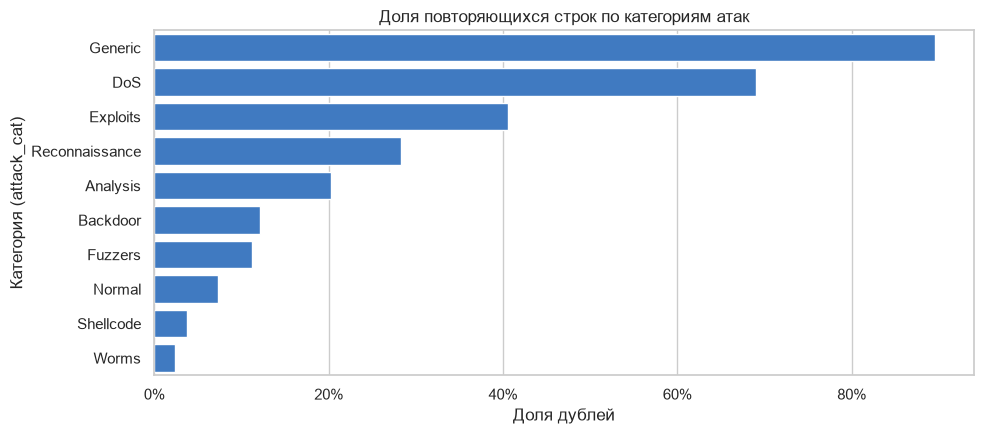

In [ ]:
# Доля дублей внутри каждой категории атак
dup_by_cat = (
    no_id.assign(is_dup=dup_mask)
         .groupby("attack_cat")["is_dup"]
         .agg(Строк="size", Доля_дублей="mean")
         .sort_values("Доля_дублей", ascending=False)
)
display(dup_by_cat.round(3))

# Горизонтальная столбчатая диаграмма доли дублей по категориям
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=dup_by_cat["Доля_дублей"], y=dup_by_cat.index, color=PALETTE["Норма"], ax=ax)
ax.set(title="Доля повторяющихся строк по категориям атак", xlabel="Доля дублей", ylabel="Категория (attack_cat)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

Пропусков в данных нет, однако **38.6% строк (67 601)** полностью повторяют
другие строки. Дубли распределены неравномерно: в категории Generic повторяется 90% записей,
в DoS - 69%, в Exploits - 41%, а среди нормального трафика - лишь 7%. Это объяснимо: генератор атак
многократно воспроизводит одни и те же сценарии, а реальные пользователи почти не создают двух
одинаковых соединений.

Ещё 940 строк противоречат друг другу: при одинаковых признаках у них разная метка. Ни одна модель
не сможет классифицировать такие записи без ошибок - это нижняя граница ошибки на этих данных.

Если оставить дубли и разбивать выборку случайно по строкам, одна и та же строка может попасть
одновременно в обучающую и проверочную часть, и качество модели на проверке будет завышено
(модель «вспомнит» ответ). При этом удалять дубли не обязательно: повторяющиеся атаки встречаются и в реальной сети
(флуд, массовое сканирование). Достаточно при разбиении следить, чтобы все копии одной строки
попадали целиком либо в обучающую, либо в проверочную часть.

### 5.2. Почти константные признаки

Некоторые признаки почти всегда равны нулю. Нужно понять, несут ли они информацию
или их можно исключить.

In [8]:
# Доля нулевых значений и число уникальных значений в признаке
const_check = pd.DataFrame({
    "Доля нулей": (df[num_cols] == 0).mean(),
    "Уникальных": df[num_cols].nunique(),
}).sort_values("Доля нулей", ascending=False).head(8)
display(const_check.round(3))

# Значения признаков, бинарных по описанию
print("is_ftp_login:", df["is_ftp_login"].value_counts().to_dict())
print("is_sm_ips_ports:", df["is_sm_ips_ports"].value_counts().to_dict())

# Доля атак при is_sm_ips_ports = 1
print("Доля атак при is_sm_ips_ports = 1:", round(df.loc[df["is_sm_ips_ports"] == 1, "label"].mean(), 3))

,Доля нулей,Уникальных
ct_ftp_cmd,0.98,4
is_ftp_login,0.98,4
is_sm_ips_ports,0.98,2
response_body_len,0.94,2386
ct_flw_http_mthd,0.90,11
trans_depth,0.90,11
dloss,0.55,370
ackdat,0.55,37708


is_ftp_login: {0: 172774, 1: 2545, 4: 16, 2: 6}
is_sm_ips_ports: {0: 172579, 1: 2762}
Доля атак при is_sm_ips_ports = 1: 0.0


1) `ct_ftp_cmd`, `is_ftp_login` и `is_sm_ips_ports` равны нулю в 98-99% строк, `response_body_len`,
`trans_depth` и `ct_flw_http_mthd` - в 90-94%. Исключать их автоматически не стоит: редкое
ненулевое значение может быть информативным. Например, при `is_sm_ips_ports = 1` в выборке нет
ни одной атаки;
2) `is_ftp_login` по описанию бинарный, однако в данных встречаются значения 2 и 4. Это ошибка
в данных; при предобработке значение стоит привести к 0/1 (`> 0`);
3) `is_ftp_login` и `ct_ftp_cmd` совпадают по смыслу и по распределению (корреляция 1.0, пункт №10),
из пары достаточно оставить один признак.

### 5.3. Порядок строк в файле

Проверяем, перемешаны ли записи в файле. Для этого строим долю атак в скользящем окне
по порядку строк: если строки перемешаны, линия должна держаться около средней доли атак.

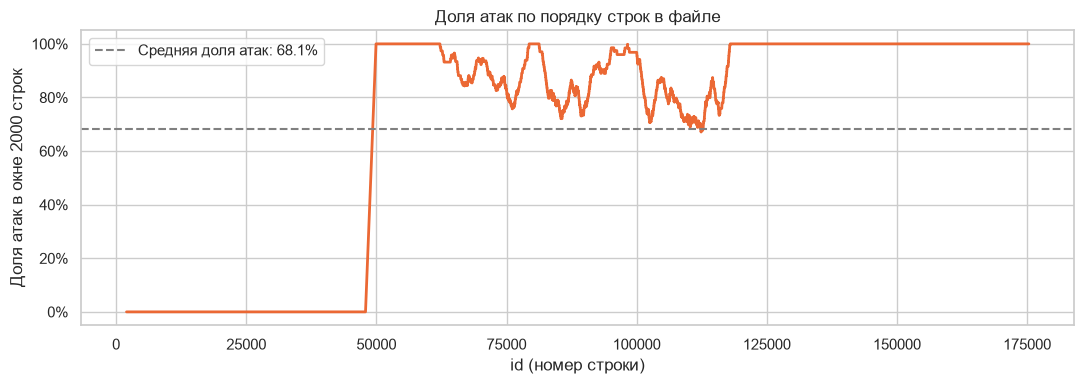

Корреляция id и label: 0.727


In [9]:
# Доля атак в скользящем окне из 2000 строк
rolling_share = df["label"].rolling(2000).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df["id"], rolling_share, color=PALETTE["Атака"], linewidth=2)
ax.axhline(df["label"].mean(), color="gray", linestyle="--", label=f"Средняя доля атак: {df['label'].mean():.1%}")
ax.set(title="Доля атак по порядку строк в файле", xlabel="id (номер строки)", ylabel="Доля атак в окне 2000 строк")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend()
plt.tight_layout()
plt.show()

print("Корреляция id и label:", round(df["id"].corr(df["label"]), 3))

Записи в файле не перемешаны. Первые ~49 000 строк - только нормальный трафик,
последние ~57 000 (примерно с 118 000-й строки) - только атаки, в середине - смесь с преобладанием атак.
Корреляция `id` с целевой переменной равна 0.727.

Из этого следуют два вывода:
1) `id` нельзя использовать как признак: модель выучит правило «большой номер - атака», которое
не имеет отношения к сетевому трафику;
2) При разбиении на обучающую и проверочную выборку данные обязательно нужно перемешивать
(`shuffle=True`) и сохранять доли классов (`stratify=y`). Разбиение «первые 80% / последние 20%»
даст проверочную выборку почти из одних атак.

## 6. Распределение целевой переменной

Смотрим соотношение классов `label` и распределение категорий атак `attack_cat`.
Для подписей на графиках вводим столбец `Класс` с расшифровкой метки.

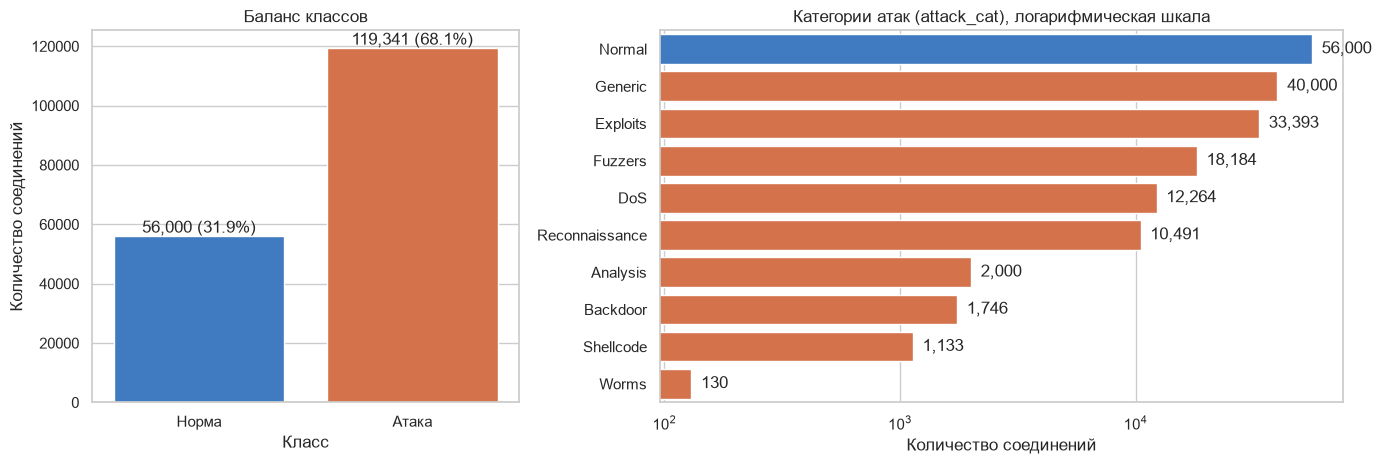

In [10]:
# Расшифровка метки для подписей на графиках
df["Класс"] = df["label"].map({0: "Норма", 1: "Атака"})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})

# Баланс классов с подписями долей
sns.countplot(data=df, x="Класс", order=ORDER, hue="Класс", palette=PALETTE, legend=False, ax=axes[0])
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():,.0f} ({p.get_height() / len(df):.1%})",
                     (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
axes[0].set(title="Баланс классов", xlabel="Класс", ylabel="Количество соединений")

# Распределение категорий атак
# Логарифмическая шкала - размеры категорий различаются в сотни раз
cat_counts = df["attack_cat"].value_counts()
colors = [PALETTE["Норма"] if c == "Normal" else PALETTE["Атака"] for c in cat_counts.index]
sns.barplot(x=cat_counts.values, y=cat_counts.index, hue=cat_counts.index, palette=colors, legend=False, ax=axes[1])
for i, v in enumerate(cat_counts.values):
    axes[1].text(v * 1.1, i, f"{v:,}", va="center")
axes[1].set_xscale("log")
axes[1].set(title="Категории атак (attack_cat), логарифмическая шкала", xlabel="Количество соединений", ylabel="")

plt.tight_layout()
plt.show()

1) Атак в выборке больше, чем нормального трафика: 119 341 (68.1%) против 56 000 (31.9%).
В реальной сети соотношение обратное - атаки составляют малую долю трафика. Соотношение классов
здесь задано составителями датасета, поэтому на него нельзя опираться как на реальную частоту
атак. Именно поэтому accuracy не подходит как метрика (пункт №2);
2) Категории атак сильно несбалансированы: Generic - 40 000 записей, Exploits - 33 393, а Worms - всего 130,
Shellcode - 1 133. Для бинарной задачи это не критично, но модель хуже научится распознавать
редкие типы атак, и их пропуски не будут заметны в общей метрике. После обучения полноту стоит
проверить отдельно по каждой категории `attack_cat`;
3) Generic и DoS одновременно самые многочисленные и самые «задублированные» категории (пункт №5.1):
если считать каждое уникальное соединение один раз, их доля заметно уменьшится.

## 7. Категориальные признаки

### 7.1. Протокол `proto`

Признак содержит 133 значения. Сравним самые частые протоколы по классам и посмотрим,
сколько протоколов встречается только в атаках.

,Количество,Доля_атак
proto,,
tcp,79946,0.51
udp,63283,0.78
unas,12084,1.00
arp,2859,0.00
ospf,2595,0.97
sctp,1150,1.00
any,300,1.00
gre,225,1.00
sun-nd,201,1.00


Протоколов, встречающихся только в атаках: 126 из 133 (26,624 соединений)


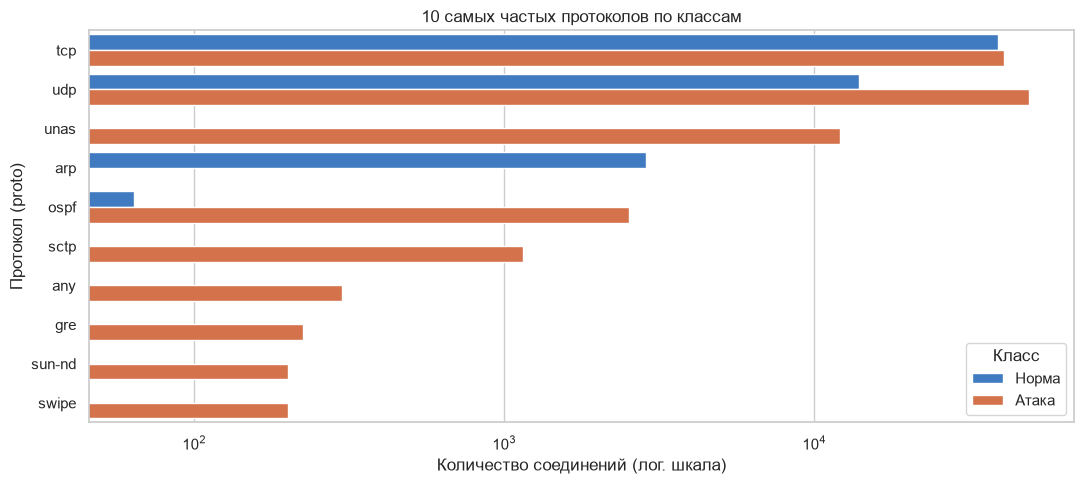

In [11]:
# Сводка по протоколам - число соединений и доля атак
proto_summary = (
    df.groupby("proto")["label"]
      .agg(Количество="size", Доля_атак="mean")
      .sort_values("Количество", ascending=False)
)
display(proto_summary.head(10).round(3))

only_attack = proto_summary[proto_summary["Доля_атак"] == 1]
print(f"Протоколов, встречающихся только в атаках: {len(only_attack)} из {len(proto_summary)} "
      f"({only_attack['Количество'].sum():,} соединений)")

# Топ-10 протоколов по классам
top_proto = proto_summary.index[:10]
fig, ax = plt.subplots(figsize=(11, 5))
sns.countplot(data=df[df["proto"].isin(top_proto)], y="proto", hue="Класс",
              order=top_proto, hue_order=ORDER, palette=PALETTE, ax=ax)
ax.set_xscale("log")
ax.set(title="10 самых частых протоколов по классам", xlabel="Количество соединений (лог. шкала)", ylabel="Протокол (proto)")
plt.tight_layout()
plt.show()

Нормальный трафик использует всего несколько протоколов: tcp, udp, arp
и немного ospf. **126 из 133 протоколов встречаются только в атаках** (26 624 соединения), в том числе
`unas` (12 084 соединения, все - атаки), `sctp`, `gre` и десятки экзотических протоколов
по ~200 записей каждый. Это поведение генератора атак, который перебирает протоколы, а в реальной
сети появление редкого протокола не обязательно означает атаку.

Для обучения 133 значения целесообразно сократить: оставить частые протоколы (tcp, udp, unas, arp, ospf)
и объединить остальные в категорию `other`. Это уменьшит размерность и снизит риск переобучения
на редких значениях.

### 7.2. Сервис `service` и состояние `state`

Сравниваем распределение классов по прикладному сервису и по состоянию соединения.
Таблицы показывают долю атак внутри каждого значения.

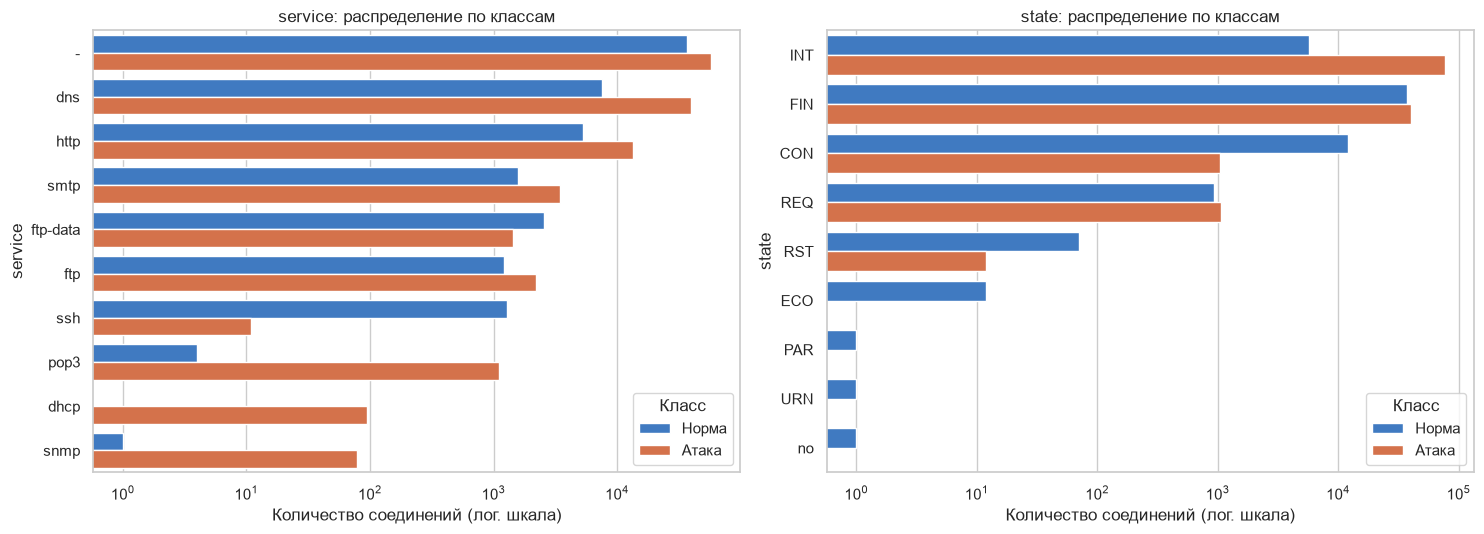

,Количество,Доля_атак
service,,
-,94168,0.61
dns,47294,0.84
http,18724,0.71
smtp,5058,0.69
ftp-data,3995,0.36
ftp,3428,0.65
ssh,1302,0.01
pop3,1105,1.00
dhcp,94,1.00


,Количество,Доля_атак
state,,
INT,82275,0.93
FIN,77825,0.52
CON,13152,0.08
REQ,1991,0.54
RST,83,0.14
ECO,12,0.00
PAR,1,0.00
URN,1,0.00
no,1,0.00


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for ax, col in zip(axes, ["service", "state"]):
    order = df[col].value_counts().index[:10]
    sns.countplot(data=df[df[col].isin(order)], y=col, hue="Класс",
                  order=order, hue_order=ORDER, palette=PALETTE, ax=ax)
    ax.set_xscale("log")
    ax.set(title=f"{col}: распределение по классам", xlabel="Количество соединений (лог. шкала)", ylabel=col)

plt.tight_layout()
plt.show()

# Доля атак внутри каждого значения
for col in ["service", "state"]:
    display(
        df.groupby(col)["label"]
          .agg(Количество="size", Доля_атак="mean")
          .sort_values("Количество", ascending=False)
          .round(3)
    )

1) `service = '-'` (сервис не распознан) - самое частое значение, 94 168 соединений, из них 61% - атаки.
Это не пропуск, а отдельное значение: соединение не удалось отнести к известному прикладному протоколу.
Кодировать его нужно как отдельную категорию, а не заменять;
2) `dns` - 84% атак: почти все DNS-соединения в выборке относятся к категории Generic. Это особенность
генератора атак, и модель может выучить правило «DNS - это атака», которое в реальной сети приведёт
к большому числу ложных тревог;
3) Некоторые сервисы почти чисты: `ssh` - менее 1% атак, а `pop3`, `dhcp`, `ssl`, `irc`, `snmp` - почти 100% атак,
но по последним всего от 25 до 1 105 записей, выводы по ним ненадёжны;
4) `state = INT` (соединение без ответа) - 93% атак, `CON` (установленное соединение) - только 8%.
Это согласуется со смыслом: многие атаки (сканирование, флуд, Generic) отправляют пакеты
без установки полноценного соединения. `state` - один из наиболее информативных категориальных
признаков;
5) Значения `PAR`, `URN`, `no` встречаются по одному разу, их стоит объединить в `other`.

## 8. Числовые признаки

### 8.1. Асимметрия распределений

Коэффициент асимметрии (skewness) показывает, насколько распределение отличается от симметричного.
Сравним распределение `sbytes` в исходной шкале и после логарифмирования `log1p(x) = log(1 + x)`
(сдвиг на единицу нужен, потому что в признаке есть нули).

,Асимметрия
trans_depth,167.30
response_body_len,76.30
sbytes,45.30
sloss,44.80
dloss,41.40
spkts,40.20
dbytes,39.80
dpkts,36.80
dinpkt,29.70
djit,29.50


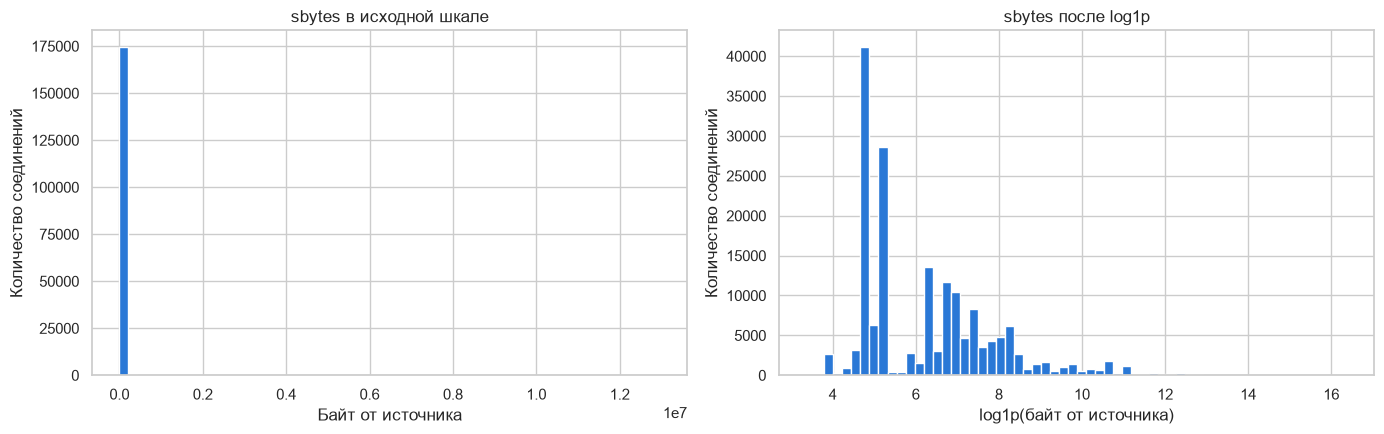

In [13]:
# 10 признаков с наибольшей асимметрией
display(df[num_cols].skew().sort_values(ascending=False).head(10).to_frame("Асимметрия").round(1))

# Распределение sbytes до и после логарифмирования
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(df["sbytes"], bins=60, color=PALETTE["Норма"])
axes[0].set(title="sbytes в исходной шкале", xlabel="Байт от источника", ylabel="Количество соединений")
axes[1].hist(np.log1p(df["sbytes"]), bins=60, color=PALETTE["Норма"])
axes[1].set(title="sbytes после log1p", xlabel="log1p(байт от источника)", ylabel="Количество соединений")
plt.tight_layout()
plt.show()

Асимметрия объёмных признаков огромна: у `sbytes` - 45, у `dbytes` - 40, у `trans_depth` - 167
(для нормального распределения она равна 0). В исходной шкале гистограмма `sbytes` вырождается
в один столбец у нуля: почти все соединения передают сотни байт, а единичные - миллионы.
После `log1p` распределение становится читаемым, видны несколько отдельных пиков - типичные размеры
соединений разных видов.

Для линейных моделей и kNN объёмные признаки (`sbytes`, `dbytes`, `spkts`, `dpkts`, `sload`, `dload`,
`rate`, `dur`) целесообразно логарифмировать. Деревьям решений логарифм не требуется: им важен только
порядок значений.

### 8.2. Распределения по классам

Строим распределения ключевых числовых признаков после `log1p` отдельно для нормы и атак.
Используется нормировка внутри класса (`common_norm=False`): классы разного размера,
и без неё распределение нормы было бы визуально «придавлено».

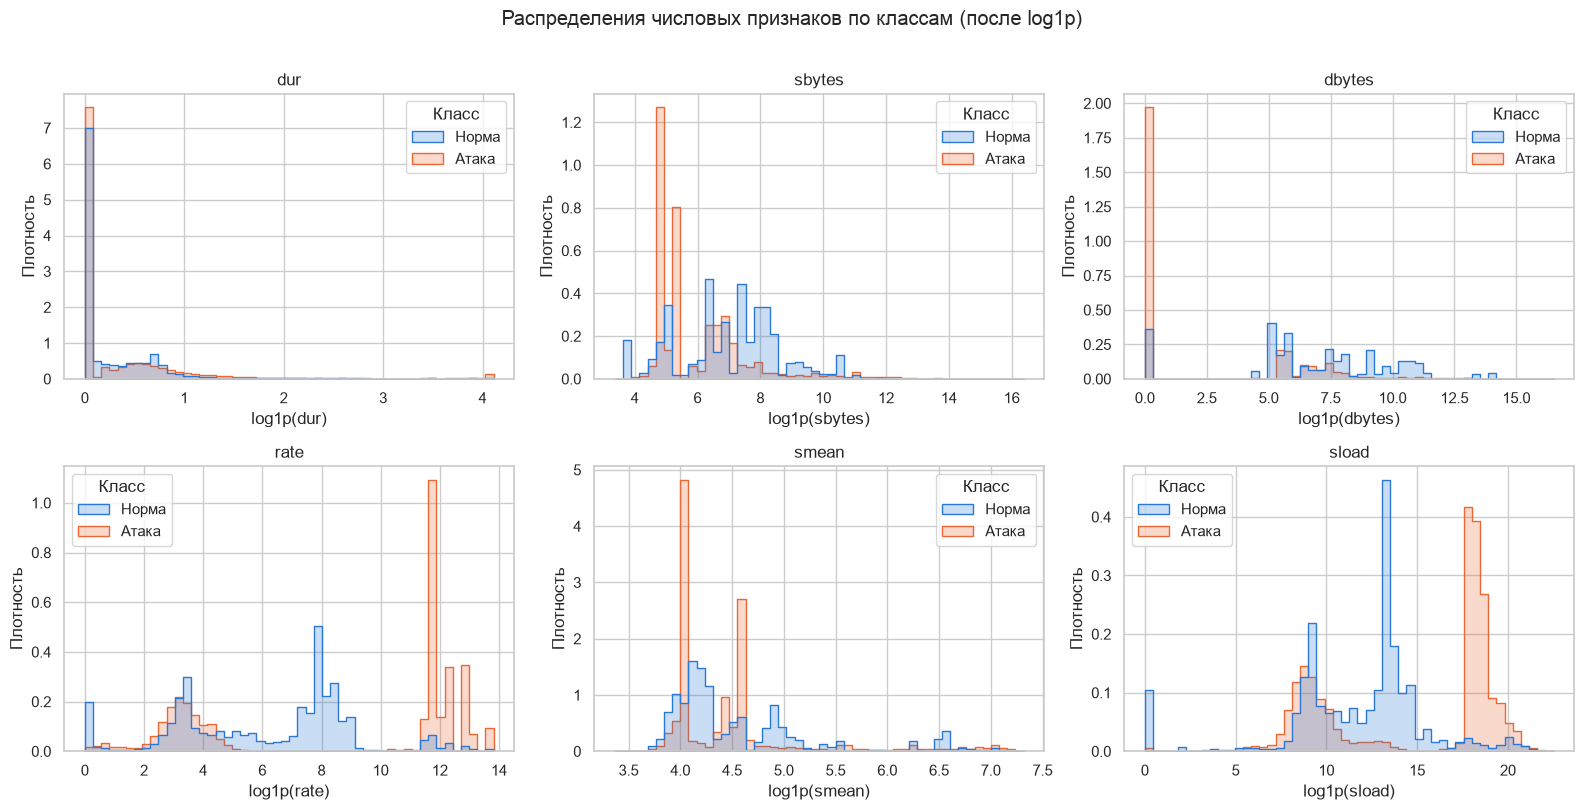

,"dur, мкс",sbytes,dbytes,rate,smean,sload
Класс,,,,,,
Норма,"38,602.50","1,470.00","1,112.00","1,382.30",73.00,"431,327.70"
Атака,9.00,200.00,0.00,"111,111.10",76.00,"50,666,664.00"


,Доля_без_ответа,Доля_короче_1мс
Класс,,
Норма,0.12,0.13
Атака,0.65,0.62


In [14]:
plot_cols = ["dur", "sbytes", "dbytes", "rate", "smean", "sload"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, plot_cols):
    sns.histplot(data=df, x=np.log1p(df[col]), hue="Класс", hue_order=ORDER, palette=PALETTE,
                 bins=50, stat="density", common_norm=False, element="step", ax=ax)
    ax.set(title=col, xlabel=f"log1p({col})", ylabel="Плотность")
plt.suptitle("Распределения числовых признаков по классам (после log1p)", y=1.01)
plt.tight_layout()
plt.show()

# Медианы по классам
# dur переводим в микросекунды, иначе медиана атак округляется до нуля
medians = df.groupby("Класс")[plot_cols].median().loc[ORDER]
medians["dur"] = medians["dur"] * 1e6
display(medians.rename(columns={"dur": "dur, мкс"}).round(1))

# Доля соединений без ответа и почти нулевой длительности
display(df.groupby("Класс").agg(
    Доля_без_ответа=("dbytes", lambda s: (s == 0).mean()),
    Доля_короче_1мс=("dur", lambda s: (s < 0.001).mean()),
).loc[ORDER].round(3))

1) Распределения нормы и атак заметно различаются. Медианная атака длится 9 микросекунд,
передаёт 200 байт и не получает ответа (`dbytes = 0`); медианное нормальное соединение длится
около 39 мс и передаёт 1.1-1.5 КБ в каждую сторону;
2) 65% атак не получают от сервера ни одного байта и 62% атак короче 1 мс, у нормального трафика -
12% и 13% соответственно. Типичная атака в датасете - короткая односторонняя посылка (сканирование,
флуд, эксплойт без ответа);
3) `rate` и `sload` у атак на порядки выше: при почти нулевой длительности число пакетов в секунду
получается огромным. Это следствие формулы (`пакеты / длительность`), а не признак высокой нагрузки;
4) Медианы `smean` у классов почти равны (73 и 76 байт), однако распределение атак состоит из узких
пиков, как и у `sbytes`: генератор отправляет пакеты фиксированного размера. Медиана такое различие
не видит, гистограмма - видит;
5) Распределения многомодальные (несколько пиков) - внутри каждого класса есть разные типы соединений.
Простая линейная граница вряд ли разделит классы хорошо, целесообразно пробовать нелинейные модели
(деревья, градиентный бустинг).

### 8.3. Выбросы

Ящик с усами показывает медиану, квартили и точки за пределами 1.5 межквартильного размаха.
Шкала `symlog` (логарифмическая с линейным участком около нуля) позволяет отобразить нули
и значения в миллионы на одном графике.

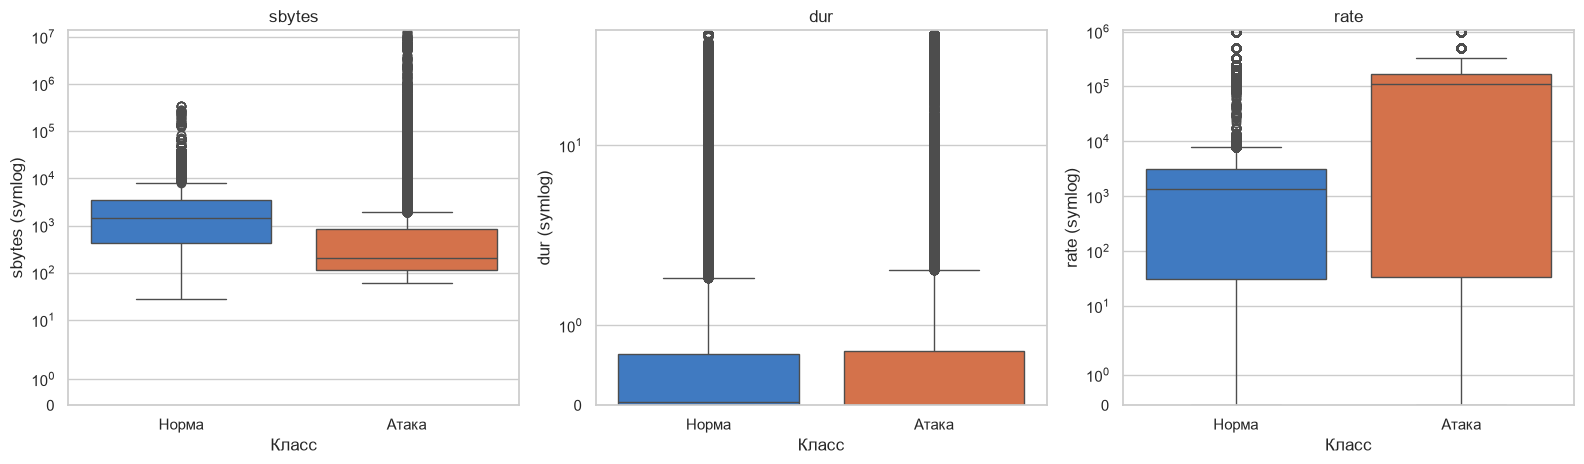

,sbytes,dur,proto,service,attack_cat
97188,12965233,59.97,tcp,smtp,Exploits
62042,12594395,59.98,tcp,smtp,Exploits
61679,12029826,59.82,tcp,smtp,Exploits
98993,11854358,59.97,tcp,smtp,Exploits
121110,11063467,59.95,tcp,smtp,Exploits


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, col in zip(axes, ["sbytes", "dur", "rate"]):
    sns.boxplot(data=df, x="Класс", y=col, order=ORDER, hue="Класс", palette=PALETTE, legend=False, ax=ax)
    ax.set_yscale("symlog")
    ax.set_ylim(bottom=0)
    ax.set(title=col, xlabel="Класс", ylabel=f"{col} (symlog)")
plt.tight_layout()
plt.show()

# Самые большие значения sbytes и категории этих соединений
display(df.nlargest(5, "sbytes")[["sbytes", "dur", "proto", "service", "attack_cat"]])

Выбросов по правилу 1.5 IQR очень много у обоих классов, но это не ошибки
измерения. Все пять крупнейших по `sbytes` соединений (11-13 млн байт) - атаки Exploits через SMTP
длительностью около 60 секунд: передача вредоносного вложения по почте. `dur` ограничен 60 секундами -
это таймаут записи соединения. Удалять такие значения нельзя: крупная передача сама по себе
может быть признаком атаки (загрузка вредоносного кода, утечка данных).

Вместо удаления выбросов целесообразно логарифмировать признаки (пункт №8.1) или использовать модели,
устойчивые к выбросам (деревья).

## 9. TTL: признак атаки или признак стенда?

TTL (time to live) пакета задаётся операционной системой отправителя (обычно 64, 128 или 255) и
уменьшается на 1 на каждом маршрутизаторе. Посмотрим, как значения `sttl` и `dttl` распределены
по классам.

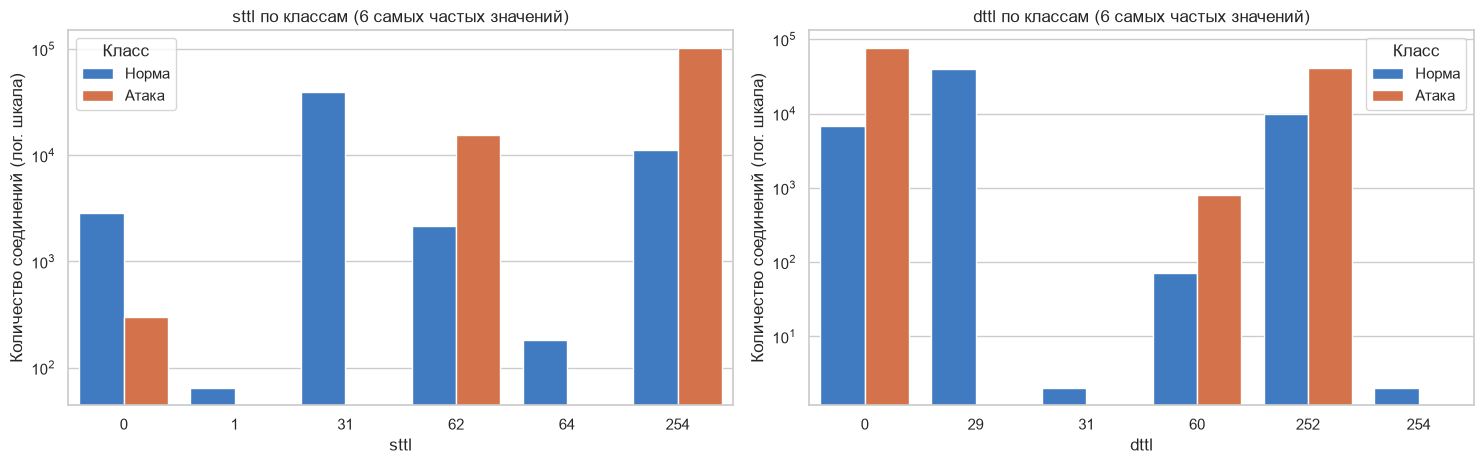

Класс,Норма,Атака,Доля атак
sttl,,,
254,11230,103513,0.90
62,2167,15514,0.88
0,2859,303,0.10
255,2,11,0.85
1,64,0,0.00
29,2,0,0.00
31,39455,0,0.00
60,6,0,0.00


Доля атак с sttl 62 или 254: 0.997
Доля нормы с sttl 62 или 254: 0.239


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, col in zip(axes, ["sttl", "dttl"]):
    top = df[col].value_counts().index[:6]
    sns.countplot(data=df[df[col].isin(top)], x=col, hue="Класс", hue_order=ORDER, palette=PALETTE, ax=ax)
    ax.set_yscale("log")
    ax.set(title=f"{col} по классам (6 самых частых значений)", xlabel=col, ylabel="Количество соединений (лог. шкала)")
plt.tight_layout()
plt.show()

# Таблица сопряжённости sttl и класса
ttl_table = pd.crosstab(df["sttl"], df["Класс"])[ORDER]
ttl_table["Доля атак"] = ttl_table["Атака"] / ttl_table.sum(axis=1)
display(ttl_table.sort_values("Атака", ascending=False).head(8).round(3))

print("Доля атак с sttl 62 или 254:", round(df.loc[df["label"] == 1, "sttl"].isin([62, 254]).mean(), 3))
print("Доля нормы с sttl 62 или 254:", round(df.loc[df["label"] == 0, "sttl"].isin([62, 254]).mean(), 3))

`sttl` почти идеально разделяет классы. 99.7% атак имеют `sttl` 62 или 254,
а значение 31 (39 455 соединений) встречается только в нормальном трафике. Корреляция `sttl`
с целевой переменной - 0.69, самая высокая среди всех признаков (пункт №10).

Однако это свойство **стенда**, а не атак. TTL определяется операционной системой и числом
маршрутизаторов между узлами: на стенде генератор атак IXIA и машины с нормальным трафиком
стоят в разных местах сети и имеют разные ОС, поэтому TTL выдаёт источник трафика. В реальной
сети злоумышленник может использовать любую ОС с любым TTL.

Если оставить `sttl`, `dttl` и производный от них `ct_state_ttl`, модель покажет очень высокое
качество на этом датасете, но может плохо работать на другом трафике. Целесообразно обучить
модель в двух вариантах - с TTL-признаками и без них - и сравнить качество. Разница покажет,
насколько модель опирается на артефакт стенда.

## 10. Корреляции

### 10.1. Корреляции между признаками

Строим матрицу корреляций Пирсона для числовых признаков. Отдельно выводим пары с |r| > 0.95 -
это признаки, практически дублирующие друг друга.

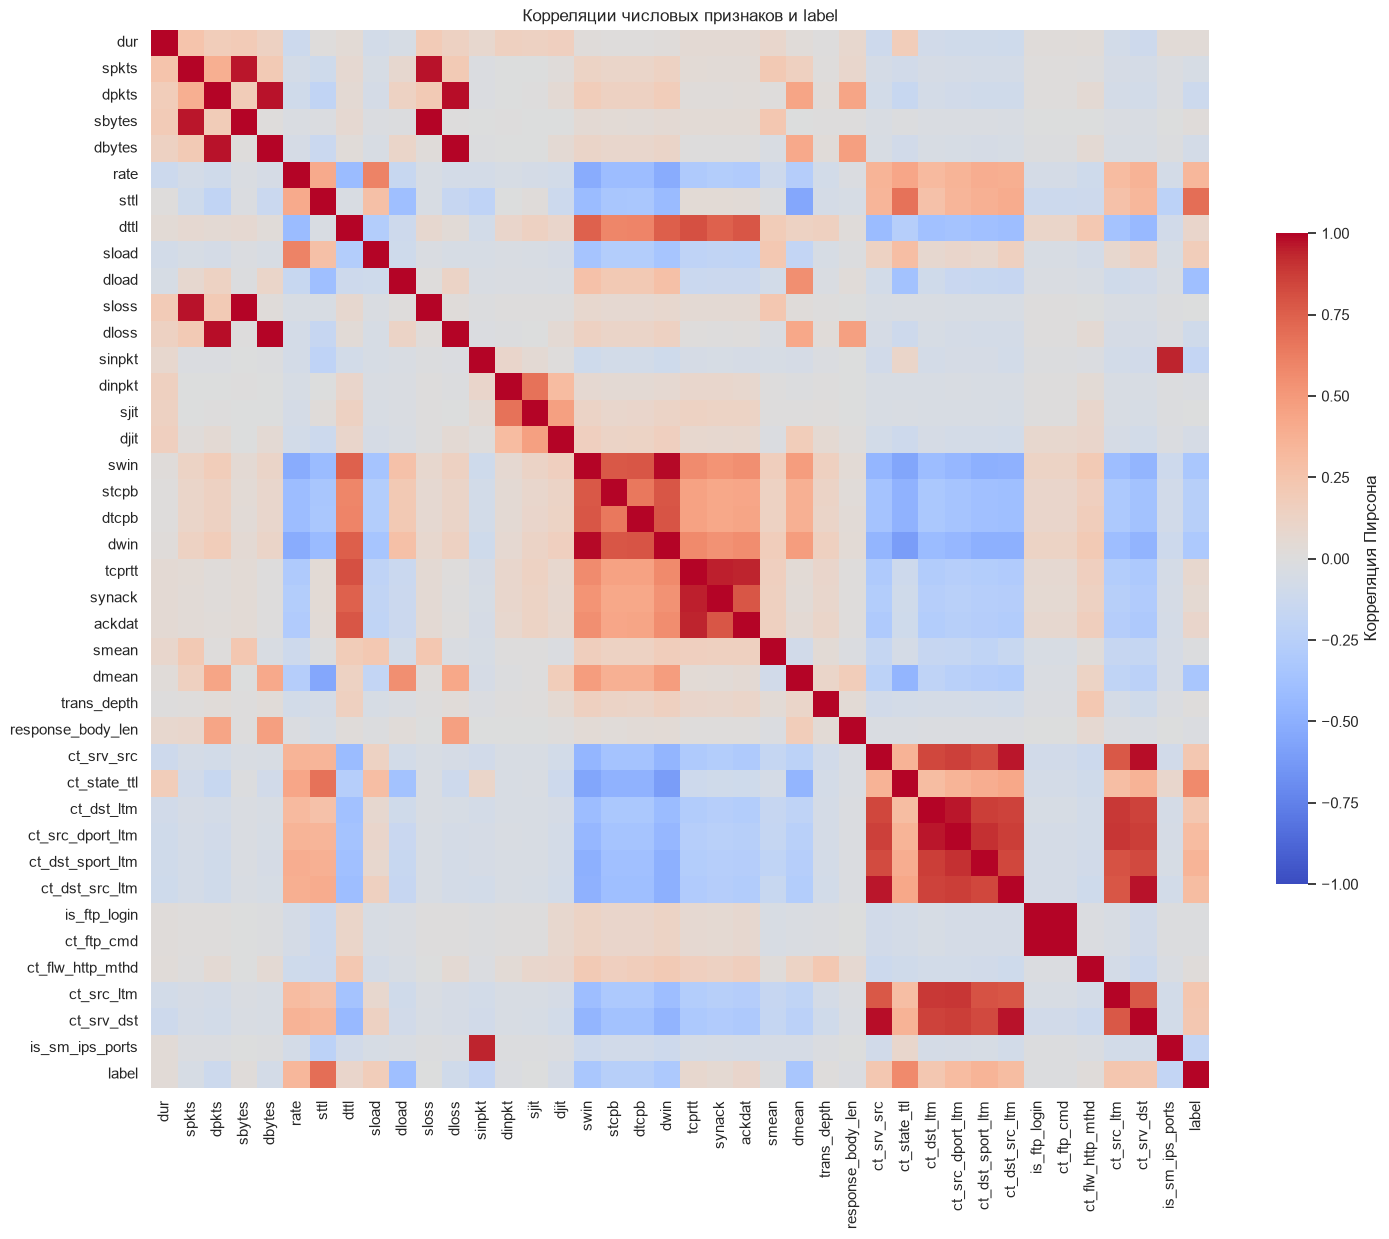

,,|r|
is_ftp_login,ct_ftp_cmd,1.00
dbytes,dloss,1.00
sbytes,sloss,1.00
swin,dwin,0.99
ct_srv_src,ct_srv_dst,0.98
dpkts,dloss,0.98
ct_dst_src_ltm,ct_srv_dst,0.97
dpkts,dbytes,0.97
spkts,sloss,0.97
ct_srv_src,ct_dst_src_ltm,0.97


In [17]:
corr = df[num_cols + ["label"]].corr()

fig, ax = plt.subplots(figsize=(15, 12.5))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"shrink": 0.6, "label": "Корреляция Пирсона"}, ax=ax)
ax.set(title="Корреляции числовых признаков и label")
plt.tight_layout()
plt.show()

# Пары признаков с |r| > 0.95 (верхний треугольник матрицы без диагонали)
upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
strong_pairs = upper.stack().loc[lambda s: s > 0.95].sort_values(ascending=False)
display(strong_pairs.to_frame("|r|").round(3))

На матрице видны блоки сильно связанных признаков. 12 пар имеют корреляцию выше 0.95:
1) `is_ftp_login` и `ct_ftp_cmd` (r = 1.0) - полностью дублируют друг друга;
2) `sbytes`, `sloss`, `spkts` и `dbytes`, `dloss`, `dpkts` (r = 0.96-0.997) - объём, число пакетов
и число потерь растут вместе: чем больше пакетов, тем больше и переданных байт, и потерянных пакетов;
3) `swin` и `dwin` (r = 0.99) - размер TCP-окна в обе стороны одинаков у большинства соединений;
4) Группа счётчиков `ct_srv_src`, `ct_srv_dst`, `ct_dst_src_ltm`, `ct_dst_ltm`, `ct_src_dport_ltm`
(r = 0.96-0.98) - они считаются по одному и тому же окну соединений.

Для линейных моделей мультиколлинеарность делает веса неустойчивыми, поэтому из каждой группы
целесообразно оставить один-два признака. Для деревьев это менее критично, но лишние признаки
замедляют обучение и размывают оценку важности признаков.

### 10.2. Связь признаков с целевой переменной

Выводим 15 признаков с наибольшей по модулю корреляцией с `label`.
Корреляция Пирсона между числовым признаком и бинарной меткой показывает,
насколько различаются средние значения признака в двух классах.

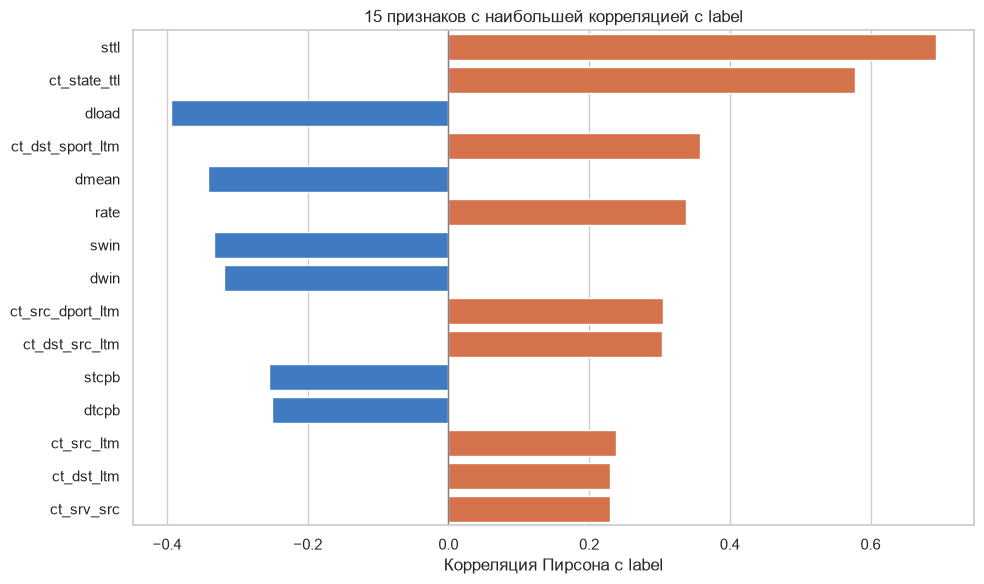

,r
sttl,0.69
ct_state_ttl,0.58
dload,-0.39
ct_dst_sport_ltm,0.36
dmean,-0.34
rate,0.34
swin,-0.33
dwin,-0.32
ct_src_dport_ltm,0.31
ct_dst_src_ltm,0.30


In [18]:
target_corr = corr["label"].drop("label")
top_target = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
colors = [PALETTE["Атака"] if v > 0 else PALETTE["Норма"] for v in top_target.values]
sns.barplot(x=top_target.values, y=top_target.index, hue=top_target.index, palette=colors, legend=False, ax=ax)
ax.axvline(0, color="gray", linewidth=1)
ax.set(title="15 признаков с наибольшей корреляцией с label", xlabel="Корреляция Пирсона с label", ylabel="")
plt.tight_layout()
plt.show()

display(top_target.to_frame("r").round(3))

1) Сильнее всего с целевой переменной связаны `sttl` (0.69) и `ct_state_ttl` (0.58) - оба основаны
на TTL, то есть на артефакте стенда (пункт №9);
2) Отрицательная связь у `dload` (-0.39), `dmean` (-0.34), `swin`/`dwin` (-0.33 / -0.32): у атак
меньше ответного трафика и реже устанавливается полноценная TCP-сессия. Это согласуется с выводом
пункта №8.2 о том, что атаки - короткие односторонние соединения;
3) `stcpb` и `dtcpb` (-0.26 / -0.25) попали в список не из-за значения порядкового номера, а из-за нулей:
у не-TCP соединений номер равен нулю, а атаки чаще используют другие протоколы (пункт №7.1);
4) Положительная связь у `rate` (0.34) и счётчиков `ct_dst_sport_ltm`, `ct_src_dport_ltm`,
`ct_dst_src_ltm` (~0.3): атаки создают много однотипных соединений к одному узлу за короткое время
(сканирование, перебор, флуд);
5) Корреляция Пирсона учитывает только линейную связь. Признаки с низкой корреляцией (например,
`sbytes`) всё равно могут быть полезны: в пункте №8.2 видно, что их распределения у классов различаются,
но не монотонно.

## 11. Итоговые выводы

**Что с данными не так:**
1) 38.6% строк - полные дубли, в основном в категориях атак Generic и DoS. Ещё 940 строк противоречат
друг другу (одинаковые признаки, разная метка);
2) Строки в файле упорядочены по классам, `id` коррелирует с меткой (r = 0.73);
3) Соотношение классов искусственное (68% атак), а внутри атак категории несбалансированы
(Worms - 130 записей против 40 000 у Generic);
4) Часть закономерностей - артефакт стенда, а не свойство атак: TTL (`sttl`, `dttl`, `ct_state_ttl`),
редкие протоколы (126 из 133 встречаются только в атаках), DNS почти полностью состоит из Generic;
5) `is_ftp_login` содержит значения 2 и 4 при бинарном описании.

**Предобработка:**
1) Удалить `id` и `attack_cat` из признаков (служебный номер и утечка ответа);
2) Дубли не удалять: повторы атак реальны. Всем копиям одной строки назначить общий номер группы;
3) Разбивать на выборки с перемешиванием и стратификацией по `label`, все копии одной строки
держать в одной части выборки;
4) `proto`: оставить частые значения, редкие объединить в `other`; `service` и `state` закодировать
one-hot, `-` в `service` оставить отдельной категорией;
5) Объёмные признаки (`sbytes`, `dbytes`, `spkts`, `dpkts`, `sload`, `dload`, `rate`, `dur`) логарифмировать
через `log1p`, для линейных моделей дополнительно стандартизировать;
6) Из групп сильно коррелирующих признаков оставить по одному-два представителя;
7) `is_ftp_login` привести к 0/1; `stcpb`, `dtcpb` заменить бинарным признаком «равен нулю» или исключить.

**Риски при обучении:**
1) Без группировки копий и перемешивания оценка качества будет завышена;
2) Модель может опираться на TTL и показывать почти идеальное качество, которое не перенесётся на
реальный трафик. Нужно сравнить модели с TTL-признаками и без них;
3) Редкие типы атак (Worms, Shellcode, Backdoor) могут пропускаться незаметно для общей метрики.
Recall нужно дополнительно проверять по каждой категории `attack_cat`;
4) Распределения многомодальные и классы разделяются нелинейно, поэтому, помимо базовой
логистической регрессии, целесообразно пробовать деревья и градиентный бустинг.